In [90]:
import geopandas as gpd
import regionmask
import xarray as xr
import os
import netCDF4
import matplotlib.pyplot as plt

In [91]:
os.environ["SHAPE_RESTORE_SHX"] = "YES"

SHAPE_RESTORE_SHX = "YES"
algeria = gpd.read_file("dz.shp")   
ds = xr.open_dataset("data_stream-moda.nc",engine="netcdf4")

mask = regionmask.mask_geopandas(algeria, ds.longitude, ds.latitude)
ds = ds.where(mask.notnull())       
ds = ds.coarsen(latitude=4, longitude=4, boundary="trim").mean()

In [92]:
df = ds.to_dataframe()
df = df.dropna()
df = df.drop(columns=['number','expver'])
df = df.drop_duplicates()
df = df.reset_index()

df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,37.05,3.85,279.584717,284.104736,-5.044459e+06,7531567.0,-5304624.0,2.157338e+06,4.281364e-04,-0.002017,2.608234,0.532738,100438.875000,0.005225
1,2015-01-01,37.05,4.25,279.160889,283.442627,-5.091602e+06,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
2,2015-01-01,37.05,6.25,279.016846,282.479736,-4.169096e+06,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
3,2015-01-01,37.05,6.65,279.395264,282.997314,-4.212256e+06,7759517.0,-4904297.0,8.162768e+05,2.184138e-04,-0.001684,2.327131,-0.065846,99208.875000,0.004700
4,2015-01-01,37.05,7.05,279.952881,283.890869,-5.019884e+06,7397582.0,-4981624.0,2.124790e+06,1.572892e-04,-0.002007,2.441242,-0.224586,100575.875000,0.005229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
198805,2026-09-01,19.45,4.25,281.478516,307.723145,-2.283744e+05,14710919.0,-10135884.0,-4.339166e+06,2.547167e-07,-0.000091,-1.002139,-1.186033,95929.562500,0.000063
198806,2026-09-01,19.45,4.65,281.372070,307.962646,-1.956674e+05,14807735.0,-10260976.0,-4.330376e+06,1.168810e-07,-0.000078,-1.043704,-1.061705,96108.375000,0.000030
198807,2026-09-01,19.45,5.05,281.207825,308.152191,-1.919864e+05,14634473.0,-10307433.0,-4.110303e+06,9.526099e-08,-0.000077,-1.165923,-0.955342,96264.546875,0.000023
198808,2026-09-01,19.45,5.45,280.963135,308.226196,-2.010040e+05,14621914.0,-10363949.0,-4.039481e+06,1.232732e-07,-0.000080,-1.308780,-0.900325,96277.953125,0.000031


In [99]:
#infos
print(df.shape)
print(df.columns.to_list())

(198810, 15)
['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


In [94]:
#kelvin to celcus
df['t2m'] = df['t2m'] - 273.15   
df['d2m'] = df['d2m'] - 273.15 

In [95]:
df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,37.05,3.85,6.434723,10.954742,-5.044459e+06,7531567.0,-5304624.0,2.157338e+06,4.281364e-04,-0.002017,2.608234,0.532738,100438.875000,0.005225
1,2015-01-01,37.05,4.25,6.010895,10.292633,-5.091602e+06,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
2,2015-01-01,37.05,6.25,5.866852,9.329742,-4.169096e+06,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
3,2015-01-01,37.05,6.65,6.245270,9.847321,-4.212256e+06,7759517.0,-4904297.0,8.162768e+05,2.184138e-04,-0.001684,2.327131,-0.065846,99208.875000,0.004700
4,2015-01-01,37.05,7.05,6.802887,10.740875,-5.019884e+06,7397582.0,-4981624.0,2.124790e+06,1.572892e-04,-0.002007,2.441242,-0.224586,100575.875000,0.005229
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
198805,2026-09-01,19.45,4.25,8.328522,34.573151,-2.283744e+05,14710919.0,-10135884.0,-4.339166e+06,2.547167e-07,-0.000091,-1.002139,-1.186033,95929.562500,0.000063
198806,2026-09-01,19.45,4.65,8.222076,34.812653,-1.956674e+05,14807735.0,-10260976.0,-4.330376e+06,1.168810e-07,-0.000078,-1.043704,-1.061705,96108.375000,0.000030
198807,2026-09-01,19.45,5.05,8.057831,35.002197,-1.919864e+05,14634473.0,-10307433.0,-4.110303e+06,9.526099e-08,-0.000077,-1.165923,-0.955342,96264.546875,0.000023
198808,2026-09-01,19.45,5.45,7.813141,35.076202,-2.010040e+05,14621914.0,-10363949.0,-4.039481e+06,1.232732e-07,-0.000080,-1.308780,-0.900325,96277.953125,0.000031


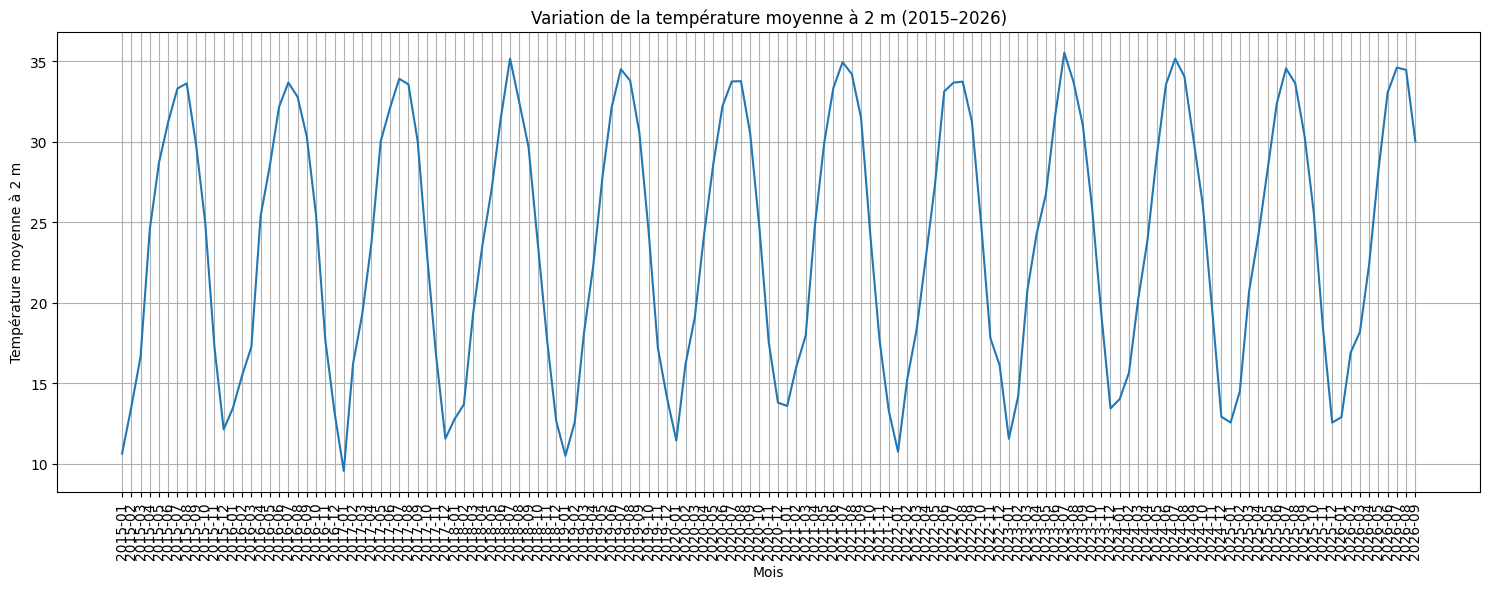

In [ ]:
import pandas as pd
#variation de la temperature moyenne a 2m chaque mois entre 2015 et 2026
df['valid_time'] = pd.to_datetime(df['valid_time'])
monthly_temp = df.groupby(
    df['valid_time'].dt.to_period('M')
)['t2m'].mean()

plt.figure(figsize=(15, 6))

plt.plot(monthly_temp.index.astype(str), monthly_temp.values)

plt.title("Variation de la température moyenne à 2 m (2015-2026)")
plt.xlabel("Mois")
plt.ylabel("Température moyenne à 2 m")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()

# univariate analysis